In [2]:
import os
os.chdir("dataset progetto finale python")
os.listdir()

['ESERCIZIO_M4-4-2_traccia_finale-products.csv',
 'ESERCIZIO_M4-4-2_traccia_finale-regions.xlsx',
 'ESERCIZIO_M4-4-2_traccia_finale-resellers.csv',
 'ESERCIZIO_M4-4-2_traccia_finale-sales.json']

# Task 1 · Python di base
## Punto 1 · Lettura dei file e strutture dati
Leggo products.csv e sales.json con Pandas e li converto conù `to_dict(orient="records")` in liste di dizionari: ogni riga diventa un dizionario {colonna: valore}. Da qui in poi lavoro solo con strutture Python, come richiesto dal vincolo.

In [3]:
import pandas as pd
prodotti=pd.read_csv("ESERCIZIO_M4-4-2_traccia_finale-products.csv").to_dict(orient="records")
vendite = pd.read_json("ESERCIZIO_M4-4-2_traccia_finale-sales.json").to_dict(orient="records")
df_regions = pd.read_excel("ESERCIZIO_M4-4-2_traccia_finale-regions.xlsx")

print(len(prodotti), len(vendite))
print(prodotti[0])

12 2000
{'ProductID': 1, 'ProductName': 'Bici Junior', 'Category': 'Outdoor', 'ListPrice': 129.0}


In [4]:
regions = {}
for r in df_regions.to_dict(orient="records"):
    regions[r["RegionID"]] = (r["State"], r["SalesRegion"])

categorie = {p["Category"] for p in prodotti}

print(regions)
print(categorie)

{1: ('Italia', 'Sud Europa'), 2: ('Francia', 'Sud Europa'), 3: ('Spagna', 'Sud Europa'), 4: ('Germania', 'Centro Europa'), 5: ('Austria', 'Centro Europa'), 6: ('Svizzera', 'Centro Europa'), 7: ('Svezia', 'Nord Europa'), 8: ('Norvegia', 'Nord Europa'), 9: ('Danimarca', 'Nord Europa')}
{'Giochi da tavolo', 'Giocattoli', 'Outdoor'}


**Risultato:** 12 prodotti, 2000 vendite, 9 regioni, 3 categorie.
Per `regions` uso una tupla come valore perché la coppia (State, SalesRegion) non deve cambiare; per le categorie uso un set perché elimina 
automaticamente i duplicati.

## Punto 2 · Fasce di prezzo
La list comprehension non supporta `elif`, quindi metto la logica if/elif/else in una funzione e la chiamo dentro la comprehension.
Soglie: Bassa < 20 €, Media ≤ 60 €, Alta > 60 €.

In [5]:
def fascia_prezzo(prezzo):
    if prezzo < 20:
        return "Bassa"
    elif prezzo <= 60:
        return "Media"
    else:
        return "Alta"

prodotti = [{**p, "Fascia": fascia_prezzo(p["ListPrice"])} for p in prodotti]

for p in prodotti:
    print(p["ProductName"], p["ListPrice"], p["Fascia"])

Bici Junior 129.0 Alta
Bici BMX 189.0 Alta
Monopattino 79.0 Alta
Pallone Calcio 19.9 Bassa
Racchette Beach 14.5 Bassa
Puzzle 1000 17.9 Bassa
Gioco dell'Oca 12.5 Bassa
Scacchi Legno 34.0 Media
Costruzioni 500 39.9 Media
Bambola Classica 24.9 Media
Robot RC 89.0 Alta
Macchinina RC 59.0 Media


**Risultato:** 4 prodotti per fascia.

## Punto 3 · Fatturato per categoria
Scrivo una funzione che, con un ciclo for, somma SalesAmount delle vendite di una categoria. Le vendite con importo mancante vengono saltate con
`continue`. Il totale viene restituito con `return`.

In [6]:
import math

def fatturato_categoria(vendite, prodotti, categoria):
    """Somma SalesAmount delle vendite di una categoria, saltando i valori mancanti."""
    id_categoria = {p["ProductID"] for p in prodotti if p["Category"] == categoria}

    totale = 0
    for v in vendite:
        importo = v["SalesAmount"]
        if v["ProductID"] not in id_categoria:
            continue
        if importo is None or math.isnan(importo):
            continue
        totale += importo
    return round(totale, 2)

for c in categorie:
    print(c, fatturato_categoria(vendite, prodotti, c)) 

Giochi da tavolo 53245.1
Giocattoli 174832.0
Outdoor 331998.4


**Risultato:** Outdoor = 331998,4 €, Giochi da tavolo = 53245,1 €, Giocattoli = 174832,0 €. 

## Punto 4 · Transazioni per superare 10.000 €
Con un ciclo while scorro le vendite nell'ordine del file e sommo gli importi finché il fatturato cumulato non supera 10.000 €.
Le vendite con importo mancante vengono contate come transazioni ma non aggiungono nulla al totale.

In [7]:
cumulato = 0
i = 0

while cumulato <= 10000 and i < len(vendite):
    importo = vendite[i]["SalesAmount"]
    if importo is not None and not math.isnan(importo):
        cumulato += importo
    i += 1

print("Transazioni necessarie:", i)
print("Fatturato cumulato:", round(cumulato, 2))

print("\nPrime cinque transazioni:")
for v in vendite[:5]:
    print(v)

Transazioni necessarie: 56
Fatturato cumulato: 10164.8

Prime cinque transazioni:
{'SalesID': 1194, 'ProductID': 6, 'RegionID': 7, 'ResellerID': 283, 'SalesDate': '2023-01-01', 'Quantity': 4.0, 'SalesAmount': 71.6}
{'SalesID': 859, 'ProductID': 6, 'RegionID': 8, 'ResellerID': 28, 'SalesDate': '2023-01-02', 'Quantity': 7.0, 'SalesAmount': nan}
{'SalesID': 1747, 'ProductID': 12, 'RegionID': 3, 'ResellerID': 281, 'SalesDate': '2023-01-02', 'Quantity': 2.0, 'SalesAmount': 118.0}
{'SalesID': 279, 'ProductID': 3, 'RegionID': 7, 'ResellerID': 128, 'SalesDate': '2023-01-02', 'Quantity': 3.0, 'SalesAmount': nan}
{'SalesID': 1470, 'ProductID': 1, 'RegionID': 6, 'ResellerID': 137, 'SalesDate': '2023-01-04', 'Quantity': 4.0, 'SalesAmount': nan}


## Definizione · Lista, tupla, set e dizionario

- **Lista** `[1, 2, 2]`: si può modificare, mantiene l'ordine, accetta duplicati. Si legge con l'indice: `lista[0]`.
- **Tupla** `(1, 2, 2)`: come la lista, ma **non** si può modificare dopo averla creata.
- **Set** `{1, 2}`: si può modificare, **non** ha ordine e
  **non** accetta duplicati. Non ha indice.
- **Dizionario** `{"a": 1}`: coppie chiave-valore, si può modificare, le chiavi non si ripetono. Si legge con la chiave: `diz["a"]`.

Nel progetto ho usato liste per prodotti e vendite, una tupla per (State, SalesRegion), un set per le categorie e un dizionario per regions.

# Task 2 · Lettura e ispezione dei dati
## Punto 1 · Struttura dei quattro file
Leggo i quattro file in DataFrame e per ciascuno guardo: dimensioni (`shape`), tipi e valori non nulli (`info`), prime e ultime righe (`head` e `tail`).

In [8]:
import numpy as np

df_products = pd.read_csv("ESERCIZIO_M4-4-2_traccia_finale-products.csv")
df_sales = pd.read_json("ESERCIZIO_M4-4-2_traccia_finale-sales.json")
df_regions = pd.read_excel("ESERCIZIO_M4-4-2_traccia_finale-regions.xlsx")
df_resellers = pd.read_csv("ESERCIZIO_M4-4-2_traccia_finale-resellers.csv")

tabelle = {"products": df_products, "sales": df_sales,
           "regions": df_regions, "resellers": df_resellers}

for nome, df in tabelle.items():
    print("=" * 50)
    print(nome.upper(), "· shape:", df.shape)
    df.info()
    display(df.head())
    display(df.tail())

PRODUCTS · shape: (12, 4)
<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ProductID    12 non-null     int64  
 1   ProductName  12 non-null     str    
 2   Category     12 non-null     str    
 3   ListPrice    12 non-null     float64
dtypes: float64(1), int64(1), str(2)
memory usage: 788.0 bytes


,ProductID,ProductName,Category,ListPrice
0,1,Bici Junior,Outdoor,129.0
1,2,Bici BMX,Outdoor,189.0
2,3,Monopattino,Outdoor,79.0
3,4,Pallone Calcio,Outdoor,19.9
4,5,Racchette Beach,Outdoor,14.5


,ProductID,ProductName,Category,ListPrice
7,8,Scacchi Legno,Giochi da tavolo,34.0
8,9,Costruzioni 500,Giocattoli,39.9
9,10,Bambola Classica,Giocattoli,24.9
10,11,Robot RC,Giocattoli,89.0
11,12,Macchinina RC,Giocattoli,59.0


SALES · shape: (2000, 7)
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   SalesID      2000 non-null   int64  
 1   ProductID    2000 non-null   int64  
 2   RegionID     2000 non-null   int64  
 3   ResellerID   2000 non-null   int64  
 4   SalesDate    2000 non-null   str    
 5   Quantity     1900 non-null   float64
 6   SalesAmount  1900 non-null   float64
dtypes: float64(2), int64(4), str(1)
memory usage: 129.0 KB


,SalesID,ProductID,RegionID,ResellerID,SalesDate,Quantity,SalesAmount
0,1194,6,7,283,2023-01-01,4.0,71.6
1,859,6,8,28,2023-01-02,7.0,NaN
2,1747,12,3,281,2023-01-02,2.0,118.0
3,279,3,7,128,2023-01-02,3.0,NaN
4,1470,1,6,137,2023-01-04,4.0,NaN


...

,RegionID,State,SalesRegion
0,1,Italia,Sud Europa
1,2,Francia,Sud Europa
2,3,Spagna,Sud Europa
3,4,Germania,Centro Europa
4,5,Austria,Centro Europa


,RegionID,State,SalesRegion
4,5,Austria,Centro Europa
5,6,Svizzera,Centro Europa
6,7,Svezia,Nord Europa
7,8,Norvegia,Nord Europa
8,9,Danimarca,Nord Europa


RESELLERS · shape: (300, 7)
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ResellerID          300 non-null    int64  
 1   RegionID            300 non-null    int64  
 2   Ordini12m           300 non-null    int64  
 3   GiorniUltimoOrdine  300 non-null    int64  
 4   ScontoMedio         300 non-null    float64
 5   Reclami             300 non-null    int64  
 6   Churn               300 non-null    int64  
dtypes: float64(1), int64(6)
memory usage: 16.5 KB


,ResellerID,RegionID,Ordini12m,GiorniUltimoOrdine,ScontoMedio,Reclami,Churn
0,1,1,14,65,0.131,1,0
1,2,7,9,149,0.117,1,0
2,3,6,21,1,0.065,2,0
3,4,4,18,162,0.011,1,1
4,5,4,22,98,0.120,0,0


,ResellerID,RegionID,Ordini12m,GiorniUltimoOrdine,ScontoMedio,Reclami,Churn
295,296,5,18,145,0.218,1,0
296,297,8,17,104,0.048,0,0
297,298,4,16,141,0.055,2,0
298,299,3,13,113,0.164,0,0
299,300,1,12,116,0.072,0,0


**Risultato:**
- products: 12 righe, 4 colonne, nessun valore mancante.
- sales: 2000 righe, 7 colonne. Quantity e SalesAmount hanno
  100 valori mancanti ciascuna (1900 non nulli su 2000).
  SalesDate è letta come testo, non come data.
- regions: 9 righe, 3 colonne, nessun valore mancante.
- resellers: 300 righe, 7 colonne, nessun valore mancante.

## Punto 2 · Statistiche e prezzo unitario
Con `describe()` guardo minimo, massimo e media di Quantity e SalesAmount. Poi trasformo le due colonne in array NumPy e calcolo il prezzo unitario di ogni vendita con una sola divisione.

In [9]:
display(df_sales[["Quantity", "SalesAmount"]].describe())

quantita = df_sales["Quantity"].to_numpy()
importi = df_sales["SalesAmount"].to_numpy()

prezzo_unitario = importi / quantita

print("Primi 10 prezzi unitari:", prezzo_unitario[:10])

,Quantity,SalesAmount
count,1900.000000,1900.000000
mean,4.966316,294.776579
std,2.206535,305.261212
min,1.000000,12.500000
25%,3.000000,89.000000
50%,5.000000,177.000000
75%,6.000000,387.000000
max,14.000000,2457.000000


Primi 10 prezzi unitari: [17.9  nan 59.   nan  nan 12.5 79.  79.  12.5  nan]


**Risultato:** Quantity va da 1 a 14 pezzi, media circa 5. SalesAmount va da 12,50 € a 2.457 €, media circa 295 €.
I prezzi unitari calcolati coincidono con i ListPrice dei prodotti, quindi i dati sono coerenti. Dove manca un valore il risultato è NaN.

## Punto 3 · Selezione con loc e iloc
Con `.loc[]` e una maschera booleana seleziono i prodotti Outdoor
con prezzo sopra 30 €. Con `.iloc[]` prendo le righe da 10 a 19
e le prime tre colonne di sales.

In [10]:
maschera = (df_products["Category"] == "Outdoor") & (df_products["ListPrice"] > 30)
display(df_products.loc[maschera])

selezione = df_sales.iloc[10:20, 0:3]
display(selezione)
print("Shape:", selezione.shape)

,ProductID,ProductName,Category,ListPrice
0,1,Bici Junior,Outdoor,129.0
1,2,Bici BMX,Outdoor,189.0
2,3,Monopattino,Outdoor,79.0


,SalesID,ProductID,RegionID
10,218,1,8
11,1136,1,9
12,1326,3,4
13,1063,9,7
14,1606,10,8
15,1283,12,1
16,98,3,4
17,156,6,8
18,1642,12,5
19,1644,4,7


Shape: (10, 3)


**Risultato:** 3 prodotti Outdoor sopra i 30 €. La selezione con iloc restituisce 10 righe e 3 colonne, come richiesto.

## Definizione · Series e DataFrame, loc e iloc

- **Series**: una sola colonna di dati, con un indice.
  Esempio: "df_sales["Quantity"]".
- **DataFrame**: una tabella con più colonne, cioè un insieme
  di Series. Esempio: `df_sales`.

- **".loc[]"**: seleziona per **etichetta** o condizione.
  Esempio: "df_products.loc[maschera]".
- **".iloc[]"**: seleziona per **posizione** numerica, come
  nelle liste. L'ultimo numero è escluso.
  Esempio: "df_sales.iloc[10:20, 0:3]".

# Task 3a · Dati mancanti, filtri e ordinamento
## Punto 1 · Conteggio dei NaN
Conto i valori mancanti per ogni colonna di sales e calcolo la percentuale sul totale delle righe. 

In [11]:
nan_prima = df_sales.isna().sum()
percentuale = nan_prima / len(df_sales) * 100

tabella_nan = pd.DataFrame({"NaN": nan_prima, "Percentuale %": percentuale.round(2)})
display(tabella_nan)

,NaN,Percentuale %
SalesID,0,0.0
ProductID,0,0.0
RegionID,0,0.0
ResellerID,0,0.0
SalesDate,0,0.0
Quantity,100,5.0
SalesAmount,100,5.0


## Punto 2 · Trattamento dei NaN
Riempio i NaN di Quantity con la mediana ed elimino le righe senza SalesAmount.

In [12]:
df_clean = df_sales.copy()

mediana = df_clean["Quantity"].median()
df_clean["Quantity"] = df_clean["Quantity"].fillna(mediana)

df_clean = df_clean.dropna(subset=["SalesAmount"])

print("Mediana:", mediana)
print("Righe rimosse:", len(df_sales) - len(df_clean))
display(df_clean.isna().sum())

Mediana: 5.0
Righe rimosse: 100


SalesID        0
ProductID      0
RegionID       0
ResellerID     0
SalesDate      0
Quantity       0
SalesAmount    0
dtype: int64

**Risultato:** mediana = 5, righe rimosse = 100. Dopo il trattamento non ci sono più NaN.

## Punto 3 · Vendite più alte
Prendo le vendite sopra il 90° percentile di SalesAmount e le
ordino per data crescente e importo decrescente.

In [13]:
soglia = df_clean["SalesAmount"].quantile(0.9)

top = df_clean.query("SalesAmount > @soglia")
top = top.sort_values(["SalesDate", "SalesAmount"], ascending=[True, False])

print("Soglia:", soglia)
print("Transazioni sopra soglia:", len(top))
display(top.head(10))

Soglia: 756.0
Transazioni sopra soglia: 162


,SalesID,ProductID,RegionID,ResellerID,SalesDate,Quantity,SalesAmount
32,1045,2,4,82,2023-01-16,6.0,1134.0
49,1872,2,7,204,2023-01-25,5.0,945.0
52,1639,1,3,299,2023-01-27,9.0,1161.0
102,296,2,9,202,2023-02-25,5.0,945.0
118,1462,2,2,224,2023-03-03,5.0,945.0
121,1221,1,8,149,2023-03-05,8.0,1032.0
123,1753,2,8,151,2023-03-05,5.0,945.0
168,283,2,2,100,2023-03-30,11.0,2079.0
217,1679,1,4,22,2023-04-27,5.0,774.0
221,832,2,4,82,2023-04-28,6.0,1134.0


**Risultato:** la soglia del 90° percentile è 756 €.
Le vendite sopra soglia sono 162, quasi tutte biciclette (ProductID 1 e 2).

## Definizione · Imputazione dei dati mancanti

**Imputazione** = sostituire un valore mancante con una stima.

- **Media**: va bene se i dati non hanno valori estremi.
  Effetto: la media resta uguale, ma i dati sembrano meno vari.
- **Mediana**: meglio se ci sono valori estremi, perché non ne
  viene influenzata. Effetto: molti valori uguali alla mediana.
- **Eliminare la riga**: meglio se i mancanti sono pochi o se il
  dato non si può stimare (come l'importo di una vendita).
  Effetto: si perdono righe, ma i dati rimasti sono reali.

Nel progetto: mediana per Quantity, eliminazione per SalesAmount.

# Task 3b · Aggregazioni e combinazione dei DataFrame
## Punto 1 · Merge
Unisco le vendite con i prodotti (su ProductID) e con le regioni
(su RegionID), usando how="left". Controllo che il numero di
righe resti uguale a quello di sales.

In [14]:
df_full = df_clean.merge(df_products, on="ProductID", how="left")
df_full = df_full.merge(df_regions, on="RegionID", how="left")

print("Righe sales:", len(df_clean))
print("Righe dopo il merge:", len(df_full))
display(df_full.isna().sum())
display(df_full.head())

Righe sales: 1900
Righe dopo il merge: 1900


SalesID        0
ProductID      0
RegionID       0
ResellerID     0
SalesDate      0
Quantity       0
SalesAmount    0
ProductName    0
Category       0
ListPrice      0
State          0
SalesRegion    0
dtype: int64

,SalesID,ProductID,RegionID,ResellerID,SalesDate,Quantity,SalesAmount,ProductName,Category,ListPrice,State,SalesRegion
0,1194,6,7,283,2023-01-01,4.0,71.6,Puzzle 1000,Giochi da tavolo,17.9,Svezia,Nord Europa
1,1747,12,3,281,2023-01-02,2.0,118.0,Macchinina RC,Giocattoli,59.0,Spagna,Sud Europa
2,947,7,8,166,2023-01-04,6.0,75.0,Gioco dell'Oca,Giochi da tavolo,12.5,Norvegia,Nord Europa
3,577,3,4,285,2023-01-04,3.0,237.0,Monopattino,Outdoor,79.0,Germania,Centro Europa
4,78,3,8,107,2023-01-04,3.0,237.0,Monopattino,Outdoor,79.0,Norvegia,Nord Europa


**Risultato:** dopo il merge le righe sono 1900, uguali a sales. Non ci sono NaN: ogni vendita ha il suo prodotto e la sua regione.

## Punto 2 · Fatturato per categoria e per regione
Con groupby() e agg() calcolo fatturato totale, quantità totale
e numero di transazioni, ordinati per fatturato decrescente.

In [15]:
per_categoria = df_full.groupby("Category").agg(
    Fatturato=("SalesAmount", "sum"),
    Quantita=("Quantity", "sum"),
    Transazioni=("SalesID", "count")
).sort_values("Fatturato", ascending=False)

per_regione = df_full.groupby("SalesRegion").agg(
    Fatturato=("SalesAmount", "sum"),
    Quantita=("Quantity", "sum"),
    Transazioni=("SalesID", "count")
).sort_values("Fatturato", ascending=False)

display(per_categoria)
display(per_regione)

,Fatturato,Quantita,Transazioni
Category,,,
Outdoor,331998.4,3800.0,767
Giocattoli,174832.0,3225.0,644
Giochi da tavolo,53245.1,2416.0,489


,Fatturato,Quantita,Transazioni
SalesRegion,,,
Centro Europa,201062.2,3413.0,698
Nord Europa,190189.0,3175.0,633
Sud Europa,168824.3,2853.0,569


**Risultato:** la categoria con il fatturato più alto è **Outdoor** (331.998,40 €). I totali per categoria coincidono con quelli calcolati nel Task 1 con fatturato_categoria().
La regione con il fatturato più alto è Centro Europa (201.062,20 €).

## Punto 3 · Vendite 2025 e concat
Separo le vendite del 2025 dalle altre con un filtro, poi le
riunisco con pd.concat() e controllo che le righe siano le stesse.

In [16]:
filtro_2025 = df_full["SalesDate"].str.startswith("2025")

vendite_2025 = df_full[filtro_2025]
vendite_altre = df_full[~filtro_2025]

ricomposto = pd.concat([vendite_2025, vendite_altre])

print("Vendite 2025:", len(vendite_2025))
print("Altre vendite:", len(vendite_altre))
print("Ricomposto:", len(ricomposto))
print("Uguale all'originale?", len(ricomposto) == len(df_full))

Vendite 2025: 640
Altre vendite: 1260
Ricomposto: 1900
Uguale all'originale? True


**Risultato:** vendite 2025 = 640, altre = 1260, totale = 1900.
La ricomposizione con concat restituisce le stesse righe dell'originale.

## Definizione · merge, join e concat

- **merge()**: unisce due tabelle usando una **colonna in comune**
  (chiave). Esempio: vendite e prodotti su ProductID.
- **join()**: come merge, ma unisce usando l'**indice** delle
  tabelle invece di una colonna.
- **concat()**: mette le tabelle **una sotto l'altra** (righe)
  oppure **una accanto all'altra** (colonne), senza cercare
  corrispondenze. Esempio: vendite 2025 + altre vendite.

# Task 3c · Serie temporali di vendita
## Punti 1 e 2 · Conversione della data e nuove colonne
Converto SalesDate da testo a data con pd.to_datetime(). Poi con l'accessor.dt ricavo anno, mese e giorno della settimana.

In [17]:
df_full["SalesDate"] = pd.to_datetime(df_full["SalesDate"])
print(df_full.dtypes)

df_full["Anno"] = df_full["SalesDate"].dt.year
df_full["Mese"] = df_full["SalesDate"].dt.month
df_full["GiornoSettimana"] = df_full["SalesDate"].dt.day_name()

display(df_full[["SalesDate", "Anno", "Mese", "GiornoSettimana"]].head())

SalesID                 int64
ProductID               int64
RegionID                int64
ResellerID              int64
SalesDate      datetime64[us]
Quantity              float64
SalesAmount           float64
ProductName               str
Category                  str
ListPrice             float64
State                     str
SalesRegion               str
dtype: object


,SalesDate,Anno,Mese,GiornoSettimana
0,2023-01-01,2023,1,Sunday
1,2023-01-02,2023,1,Monday
2,2023-01-04,2023,1,Wednesday
3,2023-01-04,2023,1,Wednesday
4,2023-01-04,2023,1,Wednesday


## Punto 3 · Fatturato mensile e variazione
Raggruppo per anno e mese, sommo il fatturato e calcolo la variazione percentuale rispetto al mese precedente.

In [18]:
mensile = df_full.groupby(["Anno", "Mese"])["SalesAmount"].sum().reset_index()
mensile = mensile.rename(columns={"SalesAmount": "Fatturato"})
mensile["Variazione %"] = (mensile["Fatturato"].pct_change() * 100).round(1)

print("Righe:", len(mensile))
display(mensile.head())
display(mensile.tail())

print("Mese con fatturato massimo:")
display(mensile.loc[mensile["Fatturato"].idxmax()])

Righe: 36


,Anno,Mese,Fatturato,Variazione %
0,2023,1,11499.8,NaN
1,2023,2,9414.9,-18.1
2,2023,3,14917.2,58.4
3,2023,4,11077.9,-25.7
4,2023,5,10806.7,-2.4


,Anno,Mese,Fatturato,Variazione %
31,2025,8,18042.4,22.0
32,2025,9,21273.2,17.9
33,2025,10,20215.7,-5.0
34,2025,11,16428.7,-18.7
35,2025,12,13776.6,-16.1


Mese con fatturato massimo:


Anno             2025.0
Mese                5.0
Fatturato       29368.3
Variazione %       37.5
Name: 28, dtype: float64

**Risultato:** la serie mensile ha 36 righe (da gennaio 2023 a
dicembre 2025). Il mese con il fatturato più alto è maggio 2025
con 29.368,30 € (+37,5% rispetto al mese prima).

## Punto 4 · Vendite recenti
Aggiungo la colonna Recente: True se la vendita è avvenuta entro 180 giorni dall'ultima data del dataset, False altrimenti.

In [19]:
ultima_data = df_full["SalesDate"].max()

giorni = (ultima_data - df_full["SalesDate"]).dt.days
df_full["Recente"] = giorni <= 180

print("Ultima data:", ultima_data)
print("Vendite recenti:", df_full["Recente"].sum())

Ultima data: 2025-12-30 00:00:00
Vendite recenti: 315


# Task 4 · Visualizzazione e storytelling
## Punto 1 · Andamento del fatturato mensile
Uso un grafico a linee perché mostra come cambia un valore nel tempo.

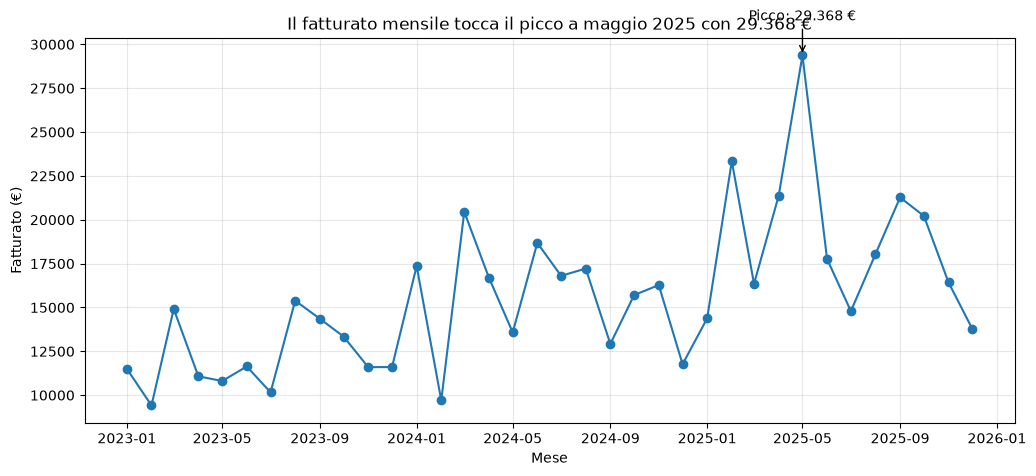

In [20]:
import matplotlib.pyplot as plt

mensile["Periodo"] = pd.to_datetime(mensile["Anno"].astype(str) + "-" + mensile["Mese"].astype(str))
picco = mensile.loc[mensile["Fatturato"].idxmax()]

plt.figure(figsize=(12, 5))
plt.plot(mensile["Periodo"], mensile["Fatturato"], marker="o")

plt.annotate("Picco: 29.368 €",
             xy=(picco["Periodo"], picco["Fatturato"]),
             xytext=(picco["Periodo"], picco["Fatturato"] + 2000),
             arrowprops=dict(arrowstyle="->"), ha="center")

plt.title("Il fatturato mensile tocca il picco a maggio 2025 con 29.368 €")
plt.xlabel("Mese")
plt.ylabel("Fatturato (€)")
plt.grid(alpha=0.3)
plt.show()

**Domanda:** come è andato il fatturato mensile tra il 2023 e il 2025?
**Risposta:** il fatturato è in crescita, con forti oscillazioni da un mese all'altro raggiungendo il picco a maggio 2025 con 29.368 €.

## Punto 2 · Boxplot per categoria
Uso il boxplot perché fa vedere come sono distribuiti gli importi in ogni categoria.

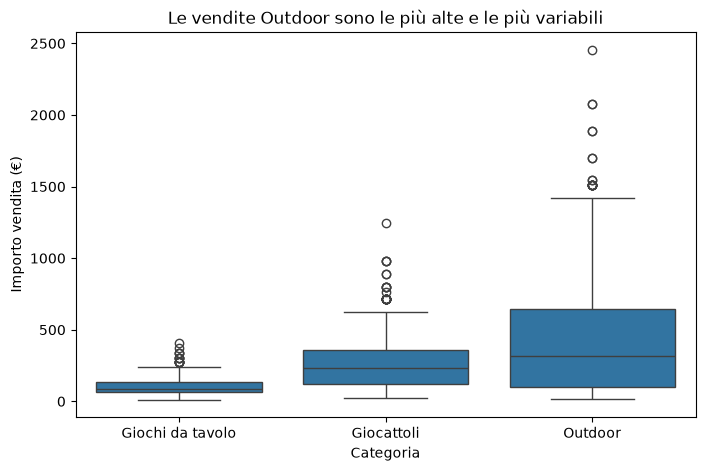

In [21]:
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.boxplot(data=df_full, x="Category", y="SalesAmount")
plt.title("Le vendite Outdoor sono le più alte e le più variabili")
plt.xlabel("Categoria")
plt.ylabel("Importo vendita (€)")
plt.show()

**Domanda:** quale categoria ha le vendite più alte?
**Risposta:** Outdoor, le sue vendite sono più alte e cambiano di più rispetto alle altre categorie.

Uso la heatmap per vedere quali variabili dei rivenditori sono collegate tra loro.

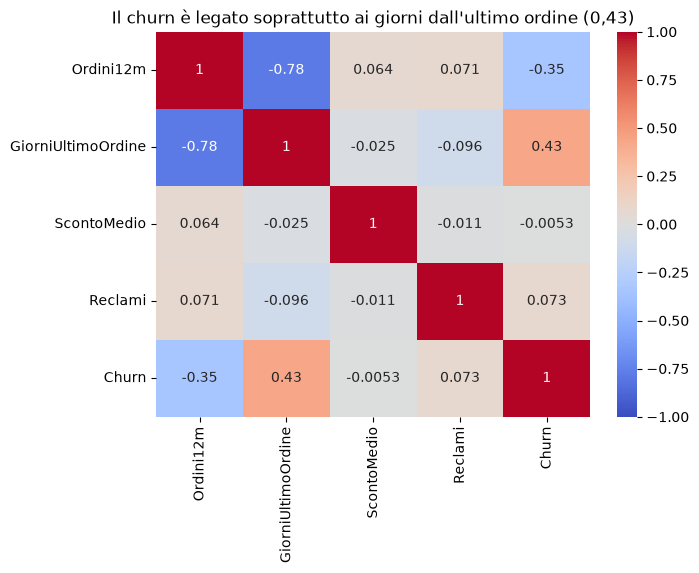

In [23]:
colonne = ["Ordini12m", "GiorniUltimoOrdine", "ScontoMedio", "Reclami", "Churn"]
correlazione = df_resellers[colonne].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(correlazione, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Il churn è legato soprattutto ai giorni dall'ultimo ordine (0,43)")
plt.show()

**Domanda:** cosa c'entra con il churn dei rivenditori?
**Risposta:** soprattutto i giorni dall'ultimo ordine (0,43): chi non ordina da tanto se ne va più spesso. Lo sconto e i reclami invece non c'entrano quasi niente.

## Definizione · Come scegliere il grafico

Il tipo di grafico dipende da cosa voglio far vedere:
- **Linee** → come cambia un valore nel tempo (es. fatturato mensile)
- **Barre** → confronto tra categorie (es. fatturato per stato)
- **Boxplot** → come sono distribuiti i valori (es. importi per categoria)
- **Heatmap o scatter** → se due variabili sono collegate (es. correlazioni dei rivenditori)

Il Plotly era opzionale e non l'ho fatto.

# Task 5 · Correlazione e regressione lineare
## Punto 1 · Correlazione
Faccio una tabella con una riga per mese: fatturato, quantità e quanti rivenditori hanno comprato. Poi guardo la correlazione.

In [24]:
dati_mese = df_full.groupby(["Anno", "Mese"]).agg(
    Fatturato=("SalesAmount", "sum"),
    Quantita=("Quantity", "sum"),
    Rivenditori=("ResellerID", "nunique")
).reset_index()

dati_mese["IndiceMese"] = range(1, len(dati_mese) + 1)

display(dati_mese.head())
display(dati_mese[["Fatturato", "Quantita", "Rivenditori"]].corr())

,Anno,Mese,Fatturato,Quantita,Rivenditori,IndiceMese
0,2023,1,11499.8,214.0,51,1
1,2023,2,9414.9,171.0,43,2
2,2023,3,14917.2,223.0,48,3
3,2023,4,11077.9,220.0,51,4
4,2023,5,10806.7,188.0,49,5


,Fatturato,Quantita,Rivenditori
Fatturato,1.000000,0.867742,0.556200
Quantita,0.867742,1.000000,0.673118
Rivenditori,0.556200,0.673118,1.000000


**Risultato:** la coppia più correlata è fatturato e quantità (0,87). Anche i rivenditori attivi sono collegati al fatturato, ma meno (0,56).

## Punti 2 e 3 · Regressione semplice e multipla
Divido i mesi in train (80%) e test (20%). Faccio due modelli: uno usa solo l'indice del mese, l'altro anche quantità e rivenditori. Poi li confronto.

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X = dati_mese[["IndiceMese", "Quantita", "Rivenditori"]]
y = dati_mese["Fatturato"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

semplice = LinearRegression().fit(X_train[["IndiceMese"]], y_train)
multipla = LinearRegression().fit(X_train, y_train)

print("SEMPLICE")
print("Coefficiente:", semplice.coef_)
print("Intercetta:", semplice.intercept_)
print("R2 train:", semplice.score(X_train[["IndiceMese"]], y_train))
print("R2 test:", semplice.score(X_test[["IndiceMese"]], y_test))

print("\nMULTIPLA")
print("Coefficienti:", multipla.coef_)
print("Intercetta:", multipla.intercept_)
print("R2 train:", multipla.score(X_train, y_train))
print("R2 test:", multipla.score(X_test, y_test))

SEMPLICE
Coefficiente: [303.57718604]
Intercetta: 10602.52906483967
R2 train: 0.4771069064080532
R2 test: -1.879053739892858

MULTIPLA
Coefficienti: [ -78.10534205   85.30543512 -229.35501331]
Intercetta: 6323.672621231086
R2 train: 0.8359739658323775
R2 test: -0.4147571881471108


| Modello | Coefficienti | Intercetta | R² train | R² test |
|---|---|---|---|---|
| Semplice | 303,58 | 10.602,53 | 0,48 | -1,88 |
| Multipla | -78,11 / 85,31 / -229,36 | 6.323,67 | 0,84 | -0,41 |

Nel modello semplice il fatturato sale di circa 304 € al mese.
La multipla va meglio sul train, ma sul test tutti e due hanno R² negativo, quindi non prevedono bene i mesi nuovi. Secondo me è perché i mesi sono pochi e il fatturato cambia tanto.

## Definizione · R²
L'R² dice quanto il modello spiega i dati. Di solito va da 0 a 1, ma sul test può venire negativo se il modello sbaglia tanto.
Un R² alto o una correlazione alta non vogliono dire che una cosa causa l'altra: dicono solo che si muovono insieme.

# Task 6a · Classificazione del churn
## Punto 1 · Preparazione
Separo le variabili (X) dal churn (y), divido in train e test con stratify e standardizzo i dati con StandardScaler.

In [28]:
from sklearn.preprocessing import StandardScaler

X = df_resellers[["Ordini12m", "GiorniUltimoOrdine", "ScontoMedio", "Reclami"]]
y = df_resellers["Churn"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(y.value_counts())

Churn
0    229
1     71
Name: count, dtype: int64


**Risultato:** 229 rivenditori restano (0) e 71 se ne vanno (1). I churn sono pochi, per questo ho usato stratify.

## Punti 2 e 3 · Regressione logistica
Alleno il modello e guardo la matrice di confusione e le metriche con soglia 0,5 e 0,3. Le confronto con la baseline, cioè dire sempre "non fa churn".

In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score

modello = LogisticRegression()
modello.fit(X_train, y_train)

prob = modello.predict_proba(X_test)[:, 1]
pred_05 = modello.predict(X_test)
pred_03 = (prob >= 0.3).astype(int)

print("SOGLIA 0.5")
print(confusion_matrix(y_test, pred_05))
print("Accuracy:", accuracy_score(y_test, pred_05))
print("Precision:", precision_score(y_test, pred_05))
print("Recall:", recall_score(y_test, pred_05))

print("\nSOGLIA 0.3")
print(confusion_matrix(y_test, pred_03))
print("Accuracy:", accuracy_score(y_test, pred_03))
print("Precision:", precision_score(y_test, pred_03))
print("Recall:", recall_score(y_test, pred_03))

print("\nBaseline (tutti 0):", (y_test == 0).mean())

SOGLIA 0.5
[[42  4]
 [10  4]]
Accuracy: 0.7666666666666667
Precision: 0.5
Recall: 0.2857142857142857

SOGLIA 0.3
[[36 10]
 [ 4 10]]
Accuracy: 0.7666666666666667
Precision: 0.5
Recall: 0.7142857142857143

Baseline (tutti 0): 0.7666666666666667


**Risultato:**

| Soglia | Accuracy | Precision | Recall |
|---|---|---|---|
| 0,5 | 0,77 | 0,50 | 0,29 |
| 0,3 | 0,77 | 0,50 | 0,71 |
| Baseline (sempre 0) | 0,77 | - | 0 |

Con soglia 0,5 il modello trova solo 4 churn su 14, con soglia 0,3 ne trova 10. L'accuracy è uguale alla baseline, quindi non basta guardare quella. Scelgo la soglia 0,3 perché per l'azienda è peggio perdere un rivenditore che fare qualche telefonata in più.

## Definizione · Precision e recall

- **Precision**: dei rivenditori che il modello dice "churn", quanti lo sono davvero.
- **Recall**: dei rivenditori che fanno davvero churn, quanti il modello ne trova.

Qui conta di più il recall, perché un churn non trovato è un cliente perso.\

# Task 6b · Segmentazione dei rivenditori con K-Means
## Punto 1 · Preparazione e inerzia
Calcolo il fatturato di ogni rivenditore, lo aggiungo alla tabella resellers e standardizzo le tre variabili. Poi provo il K-Means con k da 1 a 10 e salvo l'inerzia.

In [32]:
from sklearn.cluster import KMeans

fatturato_riv = df_full.groupby("ResellerID")["SalesAmount"].sum().reset_index()
fatturato_riv = fatturato_riv.rename(columns={"SalesAmount": "Fatturato"})

df_seg = df_resellers.merge(fatturato_riv, on="ResellerID", how="left")
df_seg["Fatturato"] = df_seg["Fatturato"].fillna(0)

dati = df_seg[["Ordini12m", "GiorniUltimoOrdine", "Fatturato"]]
dati_std = StandardScaler().fit_transform(dati)

inerzie = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(dati_std)
    inerzie.append(km.inertia_)

print(inerzie)

C:\Users\kevin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\kevin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\kevin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\kevin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

[899.9999999999998, 433.72750333980525, 319.21923309976285, 257.17481925478853, 225.59117387777565, 198.576353078213, 180.6554583425157, 164.7684849860659, 149.72101679837468, 137.02826424795944]


C:\Users\kevin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\kevin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


## Punto 2 · Metodo del gomito
Faccio il grafico dell'inerzia per k da 1 a 10 e scelgo k dove la curva smette di scendere tanto (il gomito).

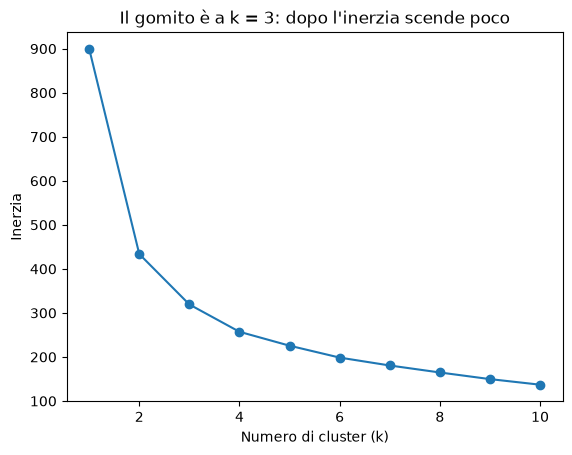

Cluster
1    137
0     95
2     68
Name: count, dtype: int64


C:\Users\kevin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


In [33]:
plt.plot(range(1, 11), inerzie, marker="o")
plt.title("Il gomito è a k = 3: dopo l'inerzia scende poco")
plt.xlabel("Numero di cluster (k)")
plt.ylabel("Inerzia")
plt.show()

km = KMeans(n_clusters=3, n_init=10, random_state=42)
df_seg["Cluster"] = km.fit_predict(dati_std)

print(df_seg["Cluster"].value_counts())

**Risultato:** scelgo k = 3 perché da 1 a 3 l'inerzia scende tanto (da 900 a 319), dopo scende poco. Aggiungere altri cluster non migliora molto.

## Punto 3 · Profilo dei cluster
Per ogni cluster calcolo la media delle variabili originali e la quota di churn, così capisco che tipo di rivenditori ci sono in ogni gruppo.

In [34]:
profilo = df_seg.groupby("Cluster").agg(
    Ordini12m=("Ordini12m", "mean"),
    GiorniUltimoOrdine=("GiorniUltimoOrdine", "mean"),
    Fatturato=("Fatturato", "mean"),
    Rivenditori=("ResellerID", "count"),
    QuotaChurn=("Churn", "mean")
).round(2)

display(profilo)

,Ordini12m,GiorniUltimoOrdine,Fatturato,Rivenditori,QuotaChurn
Cluster,,,,,
0,19.58,48.35,1514.70,95,0.11
1,12.42,141.48,1288.47,137,0.39
2,21.66,45.90,3524.38,68,0.10


nomi = {0: "Clienti regolari", 1: "Clienti a rischio", 2: "Clienti top"}
profilo["Nome"] = profilo.index.map(nomi)
display(profilo)

**Risultato:**
- Cluster 0 · Clienti regolari: ordinano spesso e da poco, churn 11%.
- Cluster 1 · Clienti a rischio: ordinano poco e non ordinano da circa 141 giorni, churn 39%.
- Cluster 2 · Clienti top: ordinano di più e hanno il fatturato più alto, churn 10%.

Il segmento con il churn più alto è **Clienti a rischio (39%)**. Secondo me l'azienda dovrebbe contattare prima questi rivenditori.

## Definizione · Centroide e inerzia

- **Centroide**: il punto centrale di un cluster, cioè la media dei rivenditori di quel gruppo.
- **Inerzia**: quanto i punti sono lontani dal loro centroide. Più è bassa, più i gruppi sono compatti.

K-Means non ha bisogno di una colonna y né di train/test perché è un metodo **non supervisionato**: non deve indovinare una risposta giusta, cerca solo gruppi simili nei dati. Quindi non c'è niente da controllare su un test.

In [35]:
# Caso 1 - codice originale
sales = df_sales
totale = 0
for v in sales["SalesAmount"]:
    totale += v
media = totale / len(sales)
print(media)

nan


# Task 7 · Debugging, refactoring e versioning
## Caso 1 · Media del fatturato

**Errore originale:** il risultato è nan invece di un numero.

**Causa:** SalesAmount ha 100 valori mancanti (NaN). Se sommi un NaN, tutto il totale diventa NaN. In più len(sales) conta anche le righe senza importo, quindi la media sarebbe comunque sbagliata.

**Prompt usato:** "Questo codice per calcolare la media del fatturato mi dà nan, perché? Come lo correggo?"

**Correzione:** uso .mean() di Pandas, che salta da solo i NaN.

In [39]:
# Caso 1 - corretto
media = df_sales["SalesAmount"].mean()
print(media)

294.7765789473684


In [37]:
# Caso 2 - codice originale
X = df_resellers[["Ordini12m", "GiorniUltimoOrdine", "ScontoMedio", "Reclami"]]
y = df_resellers["Churn"]

scaler = StandardScaler()
X_s = scaler.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X_s, y)

## Caso 2 · Preparazione del modello

**Errore originale:** nessun messaggio di errore, ma è una pratica scorretta.

**Causa:** lo scaler fa fit su tutti i dati prima della divisione, quindi usa anche le informazioni del test (data leakage). In più manca random_state, quindi ogni volta la divisione cambia.

**Prompt usato:** "Questo codice funziona ma mi hanno detto che è sbagliato, cosa c'è che non va?"

**Correzione:** prima divido in train e test, poi faccio fit dello scaler solo sul train e transform sul test, come nel Task 6a.

In [38]:
# Caso 2 - corretto
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(X_train.shape, X_test.shape)

(240, 4) (60, 4)


# Caso 3 - codice originale
df = df_full
alte = df[df["SalesAmount"] > 500 and df["Category"] == "Bikes"]
print(alte.shape)

## Caso 3 · Filtro vendite Bikes

**Errore originale:** ValueError: The truth value of a Series is ambiguous.

**Causa:** con Pandas non si può usare and tra due colonne, bisogna usare & e mettere ogni condizione tra parentesi. In più la categoria "Bikes" non esiste: le bici hanno "Bici" nel nome del prodotto.

**Prompt usato:** "Mi dà questo errore: The truth value of a Series is ambiguous. Cosa vuol dire e come lo correggo?"

**Correzione:** uso & con le parentesi e cerco le bici con str.contains("Bici") su ProductName.

In [41]:
# Caso 3 - corretto
alte = df_full[(df_full["SalesAmount"] > 500) & (df_full["ProductName"].str.contains("Bici"))]
print(alte.shape)

(250, 16)


**Risultato:** le vendite di bici sopra 500 € sono 250.

## Caso 4 · Funzione di report

**Errore originale:** nessun errore, ma il codice non si capisce: nomi f, d, x e colonne indicate con numeri.

**Causa:** con iloc e i numeri non si sa quali colonne si usano. La colonna 3 è ResellerID, ma filtrare per ID non ha senso: secondo me si voleva Quantity.

**Prompt usato:** "Puoi rendere questa funzione più chiara con nomi espliciti e una docstring?"

**Correzione:** do nomi chiari alla funzione e ai parametri, uso i nomi delle colonne e aggiungo la docstring.

Codice originale:
```python
def f(d, x):
    return d[d.iloc[:, 3] > x].iloc[:, 6].sum()
```

In [42]:
# Caso 4 - corretto
def fatturato_sopra_quantita(vendite, quantita_minima):
    """Restituisce il fatturato totale delle vendite con quantità maggiore di quantita_minima."""
    filtro = vendite["Quantity"] > quantita_minima
    return vendite[filtro]["SalesAmount"].sum()

print(fatturato_sopra_quantita(df_full, 10))

21399.2


**Risultato:** il fatturato delle vendite con più di 10 pezzi è 21.399,20 €.